<a href="https://colab.research.google.com/github/camaleonica/VenomScope/blob/main/Notebook1_Catalogo_regional.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Parte 1: Construcción del catálogo regional**
## Trabajo Práctico Obligatorio - Inteligencia Artificial - UADE

## Qué estamos construyendo
Nuestro producto, **VenomScope**, ayuda a un laboratorio a decidir **qué péptidos de la
fauna del noreste argentino vale la pena investigar**.

El problema que resuelve: cuando un laboratorio hace una campaña de muestreo, termina con
decenas o cientos de secuencias peptídicas. Analizarlas una por una lleva horas de búsqueda
manual, así que en la práctica se estudian las que a alguien le llamaron la atención y el
resto queda en una planilla que nadie vuelve a abrir. El error caro no es clasificar mal:
es gastar meses de laboratorio en el candidato equivocado, o dejar enterrado justamente el
que no se parecía a nada conocido.

Nuestra plataforma recibe una secuencia y devuelve, en segundos, a qué familia conocida se
parece, qué tan novedosa es respecto del catálogo regional y qué prioridad merece.

## Qué hace esta parte
En este notebook, construimos la materia prima: el catálogo de secuencias contra el cual el sistema va a comparar todo lo que reciba después.
Al terminar de ejecutarlo tenemos:


*   Un archivo `catalogo_nea.csv` limpio y listo para usar,

*   **El diagnóstico de con cuántos datos contamos realmente**, que es lo
  que condiciona todas las decisiones de modelado que vienen después.

Decidimos separar el trabajo en dos notebooks por una razón práctica: este tarda en
descargar pero se corre una sola vez, mientras que el del modelo lo vamos a correr muchas
veces mientras probamos cosas. Mezclarlos nos obligaría a volver a bajar todo cada vez.



## Un poco de contexto
Para que este notebook se entienda sin saber nada de biología, dejamos aquí explicados los
tres conceptos que usamos todo el tiempo.

### 1. Qué es una secuencia de proteína

Una proteína (o un péptido, que es simplemente una proteína corta) es una **cadena de
aminoácidos**. Existen 20 aminoácidos estándar y a cada uno se le asigna una letra. Así que
una proteína se escribe como una palabra larguísima:

```
MKTLLLTLVVVTIVCLDLGYTLKCHNTQLPFIYKTCPEGKNLCFKATLKKFPLKFPVKRGCAATCPKSSLLVKVVCCKTDKCN
```

Eso es todo lo que vamos a usar como entrada: **texto**. Esto es importante para nuestro
trabajo, porque significa que podemos aplicar técnicas pensadas para lenguaje natural, que
es justamente lo que hacen los modelos de embeddings que vamos a usar en el Notebook 2.

### 2. Qué es UniProt

**UniProt** es la base de datos pública de secuencias de proteínas más usada del mundo. La
mantiene un consorcio de instituciones europeas y estadounidenses, es gratuita y se puede
consultar por internet sin registrarse.

Tiene dos partes, y la diferencia nos importa mucho:


| Parte | Qué es | Calidad |
|---|---|---|
| **Swiss-Prot** | Entradas revisadas **a mano** por curadores expertos | Alta, pero son muchas menos |
| **TrEMBL** | Entradas anotadas automáticamente, sin revisión humana | Muchísimas más, pero con errores |

En nuestras consultas, el filtro `reviewed:true` significa "dame solo Swiss-Prot".
**Decidimos empezar solo con Swiss-Prot**: preferimos pocos datos confiables a muchos datos
dudosos, porque todo lo que construyamos después hereda los errores de esta etapa.

### 3. Qué es Tox-Prot y la palabra clave KW-0800

Dentro de Swiss-Prot existe un programa llamado **Tox-Prot**, dedicado específicamente a
anotar toxinas de origen animal. Todas esas entradas llevan la etiqueta (*keyword*)
**KW-0800, "Toxin"**.

Esa etiqueta es la que nos permite pedir "todas las toxinas anotadas de tal género" en vez
de tener que filtrar a mano miles de proteínas irrelevantes.



# 0. Chequeo del entorno


In [1]:
import sys, platform
import requests
import pandas as pd

print("Python :", sys.version.split()[0])
print("Sistema:", platform.system())
print("pandas :", pd.__version__)

# Prueba de conexión a UniProt
try:
    r = requests.get(
        "https://rest.uniprot.org/uniprotkb/search",
        params={"query": "accession:P00761", "format": "tsv", "fields": "accession", "size": 1},
        timeout=30,
    )
    r.raise_for_status()
    print("\nConexión a UniProt: OK")
except Exception as e:
    print("\nConexión a UniProt: FALLÓ ->", type(e).__name__, e)
    print("Si están en Colab esto no debería pasar. Revisen la red antes de continuar.")

Python : 3.13.18
Sistema: Linux
pandas : 2.2.3

Conexión a UniProt: OK


# 1. El catálogo regional

Esta es la **primera decisión de producto** del trabajo.

Empezamos pensando solo en **serpientes**, que es lo primero que a una se le viene a la
cabeza cuando piensa en toxinas. Pero al mirar el problema desde el lado del negocio nos
dimos cuenta de que nos estábamos limitando sin motivo: la piel de los **anfibios** es una
de las fuentes históricas de péptidos antimicrobianos, y los **insectos** aportan una
química completamente distinta.

Con los cuatro grupos, VenomScope deja de ser "un clasificador de serpientes" y pasa a ser
una **plataforma de bioprospección regional**. Es el mismo trabajo técnico, pero la
propuesta de valor es mucho más grande.

El **criterio final**: géneros con presencia documentada en Chaco, Formosa, Corrientes,
Misiones y norte de Santa Fe, repartidos en **serpientes, arácnidos, anfibios e insectos**.




In [2]:
# Cada elemento es (género, grupo, por qué lo incluimos).
# La tercera columna no la usa el código: está para que se entienda el criterio al leerlo.
CATALOGO = [
    # --- Serpientes ---
    ("Bothrops",      "serpiente", "yarará; el género con más accidentes en el NEA"),
    ("Crotalus",      "serpiente", "cascabel"),
    ("Micrurus",      "serpiente", "coral"),
    ("Philodryas",    "serpiente", "culebra verde; muy poco estudiada, nos interesa por eso"),

    # --- Arácnidos: arañas y escorpiones ---
    ("Tityus",        "escorpion", "escorpión; T. trivittatus es el relevante en el NEA"),
    ("Bothriurus",    "escorpion", "escorpión nativo, baja relevancia clínica"),
    ("Latrodectus",   "arana",     "viuda negra"),
    ("Loxosceles",    "arana",     "araña de rincón"),
    ("Phoneutria",    "arana",     "araña errante; presente en Misiones"),
    ("Acanthoscurria","arana",     "tarántula sudamericana"),
    ("Grammostola",   "arana",     "tarántula; sus péptidos están muy estudiados"),

    # --- Anfibios: fuente clásica de péptidos antimicrobianos ---
    ("Rhinella",      "anfibio",   "sapo común; las entradas viejas figuran como 'Bufo'"),
    ("Phyllomedusa",  "anfibio",   "rana mono; de acá salieron las dermaseptinas"),
    ("Pithecopus",    "anfibio",   "se separó de Phyllomedusa en 2016"),
    ("Leptodactylus", "anfibio",   "ranas criollas, muy presentes en el NEA"),
    ("Boana",         "anfibio",   "rana arborícola"),
    ("Hypsiboas",     "anfibio",   "nombre anterior de Boana; lo consultamos aparte, ver nota"),

    # --- Insectos: avispas, hormigas y una oruga ---
    ("Polybia",       "insecto",   "avispa social neotropical"),
    ("Polistes",      "insecto",   "avispa papelera"),
    ("Agelaia",       "insecto",   "avispa social neotropical"),
    ("Solenopsis",    "insecto",   "hormiga colorada"),
    ("Dinoponera",    "insecto",   "hormiga gigante; presente en Misiones"),
    ("Apis",          "insecto",   "abeja melífera; OJO: es introducida, no nativa"),
    ("Lonomia",       "insecto",   "oruga; accidentes graves documentados en Misiones"),
]

# Especies que confirmamos que están efectivamente en el NEA.
# IMPORTANTE: esto ETIQUETA, no filtra. Sirve para poder decir con números qué parte del
# catálogo es regional de verdad y qué parte son parientes del mismo género.
# La vamos completando a medida que confirmamos especies con bibliografía.
ESPECIES_NEA = {
    "Bothrops diporus", "Bothrops alternatus", "Bothrops jararaca",
    "Crotalus durissus", "Micrurus pyrrhocryptus", "Micrurus frontalis",
    "Tityus trivittatus", "Latrodectus mactans", "Loxosceles laeta",
    "Phoneutria nigriventer", "Rhinella arenarum",
    "Phyllomedusa sauvagii", "Leptodactylus latrans",
    "Polybia paulista", "Solenopsis invicta", "Lonomia obliqua",
}

GRUPOS = sorted({g for _, g, _ in CATALOGO})
print(f"{len(CATALOGO)} géneros repartidos en {len(GRUPOS)} grupos\n")
for grupo in GRUPOS:
    miembros = [g for g, gr, _ in CATALOGO if gr == grupo]
    print(f"  {grupo:10s} ({len(miembros):2d}): {', '.join(miembros)}")

24 géneros repartidos en 5 grupos

  anfibio    ( 6): Rhinella, Phyllomedusa, Pithecopus, Leptodactylus, Boana, Hypsiboas
  arana      ( 5): Latrodectus, Loxosceles, Phoneutria, Acanthoscurria, Grammostola
  escorpion  ( 2): Tityus, Bothriurus
  insecto    ( 7): Polybia, Polistes, Agelaia, Solenopsis, Dinoponera, Apis, Lonomia
  serpiente  ( 4): Bothrops, Crotalus, Micrurus, Philodryas


---

# 2. La descarga

### Cómo se arma la consulta

Le pedimos a UniProt las secuencias que cumplen **todas** estas condiciones a la vez:

| Pedazo de la consulta | Qué significa |
|---|---|
| `keyword:KW-0800` | que esté anotada como toxina (el programa Tox-Prot) |
| `organism_name:"Bothrops"` | que venga de un organismo de ese género |
| `reviewed:true` | que sea Swiss-Prot, o sea revisada a mano |

Y le pedimos que nos devuelva ciertos campos: el identificador, el nombre de la proteína,
el organismo, la familia a la que pertenece, el largo y —lo que de verdad nos importa— la
**secuencia**.

### Dos decisiones de implementación

**Usamos el endpoint `stream` en vez de `search`.** La diferencia: `search` devuelve los
resultados de a 25 y hay que ir pidiendo página por página, mientras que `stream` devuelve
todo junto. Como nuestras consultas son pequeñas (un género por vez), `stream` nos ahorra
código y posibles errores de paginación.

Pedimos un género por vez y esperamos un segundo entre consultas.

In [3]:
import time

# Si alguna vez queremos probar con datos sin revisar, cambiamos esto a False.
SOLO_CURADAS = True

# Los campos que le pedimos a UniProt. El que de verdad necesitamos es 'sequence';
# el resto es contexto para poder analizar y explicar lo que tenemos.
CAMPOS = ("accession,id,protein_name,organism_name,organism_id,"
          "protein_families,length,sequence,reviewed,fragment")


def descargar_genero(genero, grupo, solo_curadas=True, timeout=120):
    """Le pide a UniProt todas las toxinas anotadas de un género.

    Devuelve una tabla (DataFrame) con una fila por secuencia.
    Si el género no tiene nada publicado, devuelve una tabla vacía: eso NO es un error.
    """
    # Armamos la consulta juntando las condiciones con AND
    partes = ["(keyword:KW-0800)", f'(organism_name:"{genero}")']
    if solo_curadas:
        partes.append("(reviewed:true)")
    query = " AND ".join(partes)

    r = requests.get(
        "https://rest.uniprot.org/uniprotkb/stream",
        params={"query": query, "fields": CAMPOS, "format": "tsv"},
        timeout=timeout,
    )
    r.raise_for_status()

    # UniProt nos contesta con texto separado por tabulaciones; lo convertimos en tabla.
    from io import StringIO
    df = pd.read_csv(StringIO(r.text), sep="\t")

    # Agregamos de qué género y grupo vino, porque la respuesta no lo trae en ese formato.
    df["genero_consultado"] = genero
    df["grupo"] = grupo
    return df


# Recorremos el catálogo género por género y vamos juntando los resultados.
frames, vacios, fallidos = [], [], []

for genero, grupo, nota in CATALOGO:
    try:
        df_g = descargar_genero(genero, grupo, SOLO_CURADAS)
        n = len(df_g)
        print(f"{genero:16s} {grupo:10s} -> {n:5d}")
        if n:
            frames.append(df_g)
        else:
            vacios.append(genero)
    except Exception as e:
        print(f"{genero:16s} {grupo:10s} -> ERROR: {type(e).__name__}: {e}")
        fallidos.append(genero)
    time.sleep(1)      # cortesía con la API pública

# Pegamos todas las tablas una debajo de la otra
crudo = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

print(f"\nTOTAL: {len(crudo)} secuencias de {len(frames)} géneros")
if vacios:
    print(f"\nSin datos en UniProt ({len(vacios)}): {', '.join(vacios)}")
if fallidos:
    print(f"\nFallaron por red ({len(fallidos)}): {', '.join(fallidos)} -> volver a correr la celda")

Bothrops         serpiente  ->   233
Crotalus         serpiente  ->   184
Micrurus         serpiente  ->    70
Philodryas       serpiente  ->     6
Tityus           escorpion  ->   177
Bothriurus       escorpion  ->     0
Latrodectus      arana      ->    12
Loxosceles       arana      ->   182
Phoneutria       arana      ->    52
Acanthoscurria   arana      ->     7
Grammostola      arana      ->    14
Rhinella         anfibio    ->     0
Phyllomedusa     anfibio    ->    30
Pithecopus       anfibio    ->    19
Leptodactylus    anfibio    ->     0
Boana            anfibio    ->     0
Hypsiboas        anfibio    ->     0
Polybia          insecto    ->     8
Polistes         insecto    ->     9
Agelaia          insecto    ->     3
Solenopsis       insecto    ->     0
Dinoponera       insecto    ->     3
Apis             insecto    ->    26
Lonomia          insecto    ->     4

TOTAL: 1039 secuencias de 18 géneros

Sin datos en UniProt (6): Bothriurus, Rhinella, Leptodactylus, Boana, Hyp

> Varios géneros nos devuelven cero secuencias. Es tentador borrarlos de la lista y seguir,
> pero decidimos dejarlos y mostrarlos aparte, porque **ese vacío es información**: son
> animales reales, presentes en la región, sobre los que simplemente no hay nada publicado.
>
> Eso es exactamente el argumento comercial de VenomScope. La fauna del NEA está
> subexplorada comparada con la del sudeste asiático o Centroamérica, que es donde se
> concentró históricamente la bioprospección. El hueco en nuestros propios datos es la
> mejor prueba de que el problema que atacamos existe.

In [4]:
# Guardamos la descarga cruda ANTES de tocar nada.
crudo.to_csv("catalogo_crudo.csv", index=False)
print("Guardado: catalogo_crudo.csv")

Guardado: catalogo_crudo.csv


# 3. Limpieza y control de calidad

Los datos que bajamos no sirven tal como vienen. Aquí aplicamos cuatro filtros, y cada uno
responde a un problema concreto que encontramos al mirar los datos.


### Los cuatro filtros y por qué están

**1. Secuencias vacías.** Algunas entradas de UniProt no traen la secuencia. Sin eso no
tenemos nada que analizar.

**2. Solo aminoácidos estándar.** Son 20 y cada uno tiene su letra. Pero en las bases de
datos aparecen otras letras: `X` significa "acá hay un aminoácido pero no sabemos cuál",
y `B`, `Z` o `U` son casos ambiguos o raros. Una secuencia con letras desconocidas le mete
ruido al modelo.

**3. Sin fragmentos.** Un "fragmento" es un pedazo incompleto de una proteína más grande,
no una molécula entera. **UniProt ya los tiene marcados**, así que no necesitamos adivinar:
se lo preguntamos directamente con el campo `fragment`.

Este filtro reemplaza al criterio que usábamos antes, que era descartar todo lo más corto
de 20 aminoácidos. La historia de por qué lo cambiamos está en la sección 3.5 y es, para
nosotras, el hallazgo más importante del notebook.

**4. Longitud entre 5 y 600 aminoácidos.** Ahora que los fragmentos se filtran por
anotación, el largo cumple un papel mucho más modesto: solo descarta los extremos. Por
arriba, proteínas grandes que no son el tipo de péptido que nos interesa. Por abajo, un
mínimo bajísimo, porque aprendimos que las secuencias cortas pueden ser muy valiosas.


In [5]:
AMINOACIDOS_VALIDOS = set("ACDEFGHIKLMNPQRSTVWY")   # los 20 estándar

# OJO con estos números: empezamos con LARGO_MIN = 20 y lo bajamos a 5 después del
# análisis de la sección 3.5. Con 20 estábamos perdiendo 167 secuencias, y resultaron
# ser justo las más valiosas del catálogo.
LARGO_MIN, LARGO_MAX = 5, 600

# UniProt devuelve los encabezados con SUS nombres ("Sequence", "Organism (ID)"...).
# Los renombramos una sola vez acá para que el resto del notebook no dependa de eso.
# Esto nos costó un rato de confusión la primera vez: el código fallaba porque buscábamos
# "sequence" en minúscula y la columna venía como "Sequence".
RENOMBRES = {
    "Entry":           "accession",        # identificador único y estable de la entrada
    "Entry Name":      "entry_name",
    "Protein names":   "nombre_proteina",
    "Organism":        "organismo",
    "Organism (ID)":   "organism_id",
    "Protein families":"familia_uniprot",  # a qué familia de proteínas pertenece
    "Length":          "largo_uniprot",
    "Sequence":        "sequence",         # ESTA es la que nos importa
    "Reviewed":        "revisada",
    "Fragment":        "es_fragmento",     # vacío = proteína completa; con texto = pedazo
}

df = crudo.rename(columns=RENOMBRES).copy()

# Si UniProt cambia un encabezado, queremos enterarnos acá y no 200 líneas más abajo.
faltantes = [c for c in ("sequence", "organismo") if c not in df.columns]
assert not faltantes, (
    f"Faltan columnas esenciales: {faltantes}. "
    f"Columnas recibidas: {list(df.columns)}. Revisar el diccionario RENOMBRES."
)

n0 = len(df)
reporte = []

def paso(nombre, df_nuevo, df_viejo):
    """Aplica un filtro y anota cuántas filas se perdieron, para poder mostrarlo después."""
    reporte.append({
        "paso": nombre,
        "quedan": len(df_nuevo),
        "se_pierden": len(df_viejo) - len(df_nuevo),
    })
    return df_nuevo

# Normalizamos: todo en mayúsculas y sin espacios al borde
df["sequence"] = df["sequence"].astype(str).str.upper().str.strip()

df = paso("sin secuencia vacía",
          df[df["sequence"].str.len() > 0], df)

df = paso("solo aminoácidos estándar",
          df[df["sequence"].apply(lambda s: set(s) <= AMINOACIDOS_VALIDOS)], df)

# Filtro por anotación experta, no por nuestro criterio: UniProt deja la columna
# 'Fragment' vacía cuando la proteína está completa, y la llena ("fragment") cuando
# lo que hay cargado es solo un pedazo.
if "es_fragmento" in df.columns:
    df = paso("sin fragmentos", df[df["es_fragmento"].isna()], df)
else:
    print("AVISO: no vino la columna 'Fragment'. ¿Está 'fragment' en CAMPOS?")

df = paso(f"largo entre {LARGO_MIN} y {LARGO_MAX}",
          df[df["sequence"].str.len().between(LARGO_MIN, LARGO_MAX)], df)

df = paso("sin secuencias duplicadas",
          df.drop_duplicates(subset="sequence"), df)

# --- Campos derivados que vamos a necesitar más adelante ---

# El campo "organismo" viene como "Bothrops diporus (yarará chica)".
# Nos quedamos con la parte científica, antes del paréntesis.
df["especie"] = df["organismo"].astype(str).str.split("(").str[0].str.strip()

df["familia_proteica"] = df.get(
    "familia_uniprot", pd.Series(index=df.index, dtype=object)
).fillna("Sin familia asignada")

# El campo de familias de UniProt NO es un nombre: es una ruta jerárquica separada
# por comas, como una carpeta. Por ejemplo:
#   "Phospholipase A2 family, Group II subfamily, D49 sub-subfamily"
# Nos quedamos con el primer nivel, que es la familia de verdad.
df["familia_nivel1"] = df["familia_proteica"].str.split(",").str[0].str.strip()

# "Sin familia asignada" no es una familia: es la FALTA de anotación. No sirve como
# clase de entrenamiento, pero esas secuencias son oro para evaluar la detección de
# novedad, así que las marcamos en vez de borrarlas.
df["familia_valida"] = df["familia_nivel1"] != "Sin familia asignada"

df["largo"] = df["sequence"].str.len()

# Marcamos los péptidos cortos. NO los descartamos: los recuperamos a propósito.
#  Pero los señalamos porque su embedding es menos confiable:
# con 10 aminoácidos hay mucha menos información que con 100, y la distancia al
# vecino más cercano se vuelve
# más ruidosa. Queremos poder medir el modelo con ellos y sin ellos.
df["peptido_corto"] = df["largo"] < 20

# Etiqueta de alcance geográfico (marca, NO filtra)
df["en_nea"] = df["especie"].isin(ESPECIES_NEA)

print(pd.DataFrame(reporte).to_string(index=False))
print(f"\nDe {n0} secuencias crudas quedaron {len(df)} ({len(df)/max(n0,1):.1%})")
print(f"Confirmadas como especies del NEA: {df['en_nea'].sum()} ({df['en_nea'].mean():.1%})")
print(f"Péptidos cortos (<20 aa) conservados: {df['peptido_corto'].sum()}")

                     paso  quedan  se_pierden
      sin secuencia vacía    1039           0
solo aminoácidos estándar    1009          30
           sin fragmentos     652         357
      largo entre 5 y 600     630          22
sin secuencias duplicadas     584          46

De 1039 secuencias crudas quedaron 584 (56.2%)
Confirmadas como especies del NEA: 91 (15.6%)
Péptidos cortos (<20 aa) conservados: 81


Un **porcentaje del NEA bajo** no está mal: significa que la mayor parte del
catálogo son parientes del mismo género que usamos como contexto, no ejemplares de la región.


# 3.5. El hallazgo: por qué cambiamos el filtro de longitud

Nuestro primer criterio fue descartar toda secuencia de menos de 20 aminoácidos, asumiendo
que lo muy corto serían fragmentos rotos. Parecía razonable.

Al mirar el reporte de limpieza vimos que ese filtro se estaba llevando **167 secuencias**,
casi una de cada cinco. Era demasiado para dejarlo pasar, así que fuimos a ver qué eran.

Primero miramos de qué lado del umbral se perdían y de qué grupo venían. Después, y esto
fue lo decisivo, miramos cómo se llamaban.

In [6]:
# Reconstruimos el análisis que nos hizo cambiar de opinión.
# Partimos del crudo y aplicamos solo los filtros previos al de longitud.
tmp = crudo.rename(columns=RENOMBRES).copy()
tmp["sequence"] = tmp["sequence"].astype(str).str.upper().str.strip()
tmp = tmp[tmp["sequence"].apply(lambda s: set(s) <= AMINOACIDOS_VALIDOS)]
tmp["largo"] = tmp["sequence"].str.len()

UMBRAL_VIEJO = 20      # el criterio original, el que resultó estar mal

cortas = tmp[tmp["largo"] < UMBRAL_VIEJO]
largas = tmp[tmp["largo"] > LARGO_MAX]

print(f"Con el umbral viejo de {UMBRAL_VIEJO} aminoácidos perdíamos:")
print(f"  por CORTAS : {len(cortas)}")
print(f"  por LARGAS : {len(largas)}\n")

print("Las cortas, por grupo:")
print(cortas["grupo"].value_counts().to_string(), "\n")

print("Distribución de longitudes de las cortas:")
print(cortas["largo"].describe().to_string(), "\n")

print("Y acá está la clave — cómo se llaman:")
print(cortas["nombre_proteina"].value_counts().head(15).to_string())

Con el umbral viejo de 20 aminoácidos perdíamos:
  por CORTAS : 167
  por LARGAS : 26

Las cortas, por grupo:
grupo
serpiente    79
anfibio      37
insecto      25
escorpion    17
arana         9 

Distribución de longitudes de las cortas:
count    167.000000
mean      11.664671
std        3.019237
min        5.000000
25%       10.000000
50%       11.000000
75%       14.000000
max       19.000000 

Y acá está la clave — cómo se llaman:
nombre_proteina
Bradykinin-potentiating peptide 13a (BPP-13a)                                5
[Thr6]-bradykinin                                                            3
Bradykinin                                                                   3
Bradykinin-potentiating peptide Phypo Xa (BPP)                               3
Bradykinin-potentiating peptide 11 (BPP-11)                                  3
Des-Arg9-[Thr6]-bradykinin (Des-Arg-[Thr6]-bradykinin)                       3
[Hyp3]-bradykinin                                                     

### Lo que encontramos

#### 1. Estábamos borrando la molécula más exitosa del campo

La mayoría de esas secuencias cortas son **péptidos potenciadores de bradiquinina (BPPs)**
y péptidos emparentados con la bradiquinina. No son fragmentos rotos: son moléculas enteras
que simplemente *son* cortas, con una distribución de longitudes demasiado consistente
(mediana de 11 aminoácidos) como para ser basura.

Y esa familia tiene una historia que conviene conocer: **el captopril**, el primer inhibidor
de la ECA, uno de los antihipertensivos más vendidos de la historia, se desarrolló a partir
de un péptido de nueve aminoácidos del veneno de *Bothrops jararaca*, una especie que
tenemos en nuestro propio catálogo.

Dicho de otra forma: con el filtro original, VenomScope habría **descartado en silencio**
la clase de molécula que dio origen al caso de éxito más importante de la bioprospección de
venenos. Un laboratorio que usara nuestra herramienta nunca se habría enterado.

#### 2. El largo era un mal criterio, en las dos direcciones

En la misma lista apareció una entrada llamada *Snake venom serine protease* con menos de
20 aminoácidos. Una serina proteasa tiene unos 230: esa entrada no es la proteína, es un
**pedazo** de ella.

O sea que entre las secuencias cortas convivían dos cosas distintas —péptidos completos y
valiosos, y fragmentos incompletos— y el largo no distingue entre las dos.

La solución fue dejar de inventar un criterio propio y usar el que ya existía: **UniProt
marca cuáles entradas son fragmentos**. Se lo preguntamos con el campo `fragment` y listo.

> Esto es más que un ajuste de parámetro. Pasamos de **filtrar por una regla nuestra** a
> **filtrar por la anotación de un curador experto**. El resultado es más preciso y, sobre
> todo, mucho más defendible.

#### 3. Una familia que cruza los grupos

Mirando los nombres apareció algo que no esperábamos: **`Phyllokinin`** y
**`[Thr6]-phyllokinin`**. La filoquinina viene de *Phyllomedusa*, la rana mono, y está
emparentada con los BPPs de serpiente.

Eso explica por qué había también 37 péptidos cortos de anfibio: **serpientes y anfibios
producen péptidos de la misma familia**, a pesar de ser grupos que no tienen nada que ver
entre sí.

Tiene una consecuencia directa sobre nuestro modelo, y preferimos anticiparla ahora:
esos péptidos van a caer **juntos** en el espacio de embeddings aunque vengan de animales
distintos. Un clasificador que intente predecir la especie se va a equivocar con ellos y
va a tener razón en equivocarse, porque biológicamente se parecen.

**Los embeddings agrupan por función, no por taxonomía.** No es un defecto: es exactamente
lo que los hace valiosos. Pero nos hizo repensar cuál es la pregunta principal que nuestro
producto debería responder.

# 4. El desbalance

Aquí vamos a ver que unos pocos géneros concentran la mayoría de las secuencias y que
muchos tienen apenas una o dos. Eso no es un error nuestro: es el **sesgo de la base de
datos**. Las especies que históricamente se estudiaron más tienen muchas más entradas
publicadas, y eso se arrastra a cualquier modelo que entrenemos encima.

Y tiene una consecuencia directa sobre nuestro producto: **una secuencia de una especie
poco estudiada va a parecer más novedosa de lo que realmente es**, simplemente porque hay
menos material con qué compararla.


In [7]:
import matplotlib.pyplot as plt

por_grupo = df["grupo"].value_counts()
por_especie = df["especie"].value_counts()

# Resumen por grupo: con cuatro grupos, esto es lo primero que hay que mirar
resumen = df.groupby("grupo").agg(
    secuencias=("sequence", "size"),
    especies=("especie", "nunique"),
    generos=("genero_consultado", "nunique"),
    largo_medio=("largo", "mean"),
).sort_values("secuencias", ascending=False)
resumen["% del catálogo"] = (resumen["secuencias"] / len(df) * 100).round(1)
resumen["largo_medio"] = resumen["largo_medio"].round(0)

print("=== Por grupo ===")
print(resumen.to_string(), "\n")

# Aviso automático: si un grupo domina, nuestras métricas van a mentirnos
dominante = resumen.index[0]
share = resumen["% del catálogo"].iloc[0]
if share > 60:
    print(f"ATENCIÓN: '{dominante}' concentra el {share}% del catálogo.")
    print("Un modelo entrenado así puede predecir siempre ese grupo y aun así tener buena")
    print("'exactitud'. Hay que evaluar con métricas por clase (macro-F1), no con exactitud.\n")

print("=== Por especie ===")
print(f"Especies distintas: {df['especie'].nunique()}")
print(f"Especies con menos de 5 secuencias: {(por_especie < 5).sum()}")
print(f"La más representada concentra el {por_especie.iloc[0]/len(df):.1%} del catálogo\n")
print("Top 10 especies:")
print(por_especie.head(10).to_string())

=== Por grupo ===
           secuencias  especies  generos  largo_medio  % del catálogo
grupo                                                                
serpiente         285        50        4        149.0            48.8
escorpion         136        13        1         78.0            23.3
arana              91        16        4        133.0            15.6
insecto            50        21        6         54.0             8.6
anfibio            22         6        1         26.0             3.8 

=== Por especie ===
Especies distintas: 106
Especies con menos de 5 secuencias: 69
La más representada concentra el 7.5% del catálogo

Top 10 especies:
especie
Tityus serrulatus               44
Bothrops jararaca               32
Crotalus durissus terrificus    27
Phoneutria nigriventer          25
Crotalus adamanteus             24
Tityus discrepans               21
Tityus obscurus                 19
Loxosceles intermedia           17
Crotalus viridis viridis        16
Crotalus atrox 

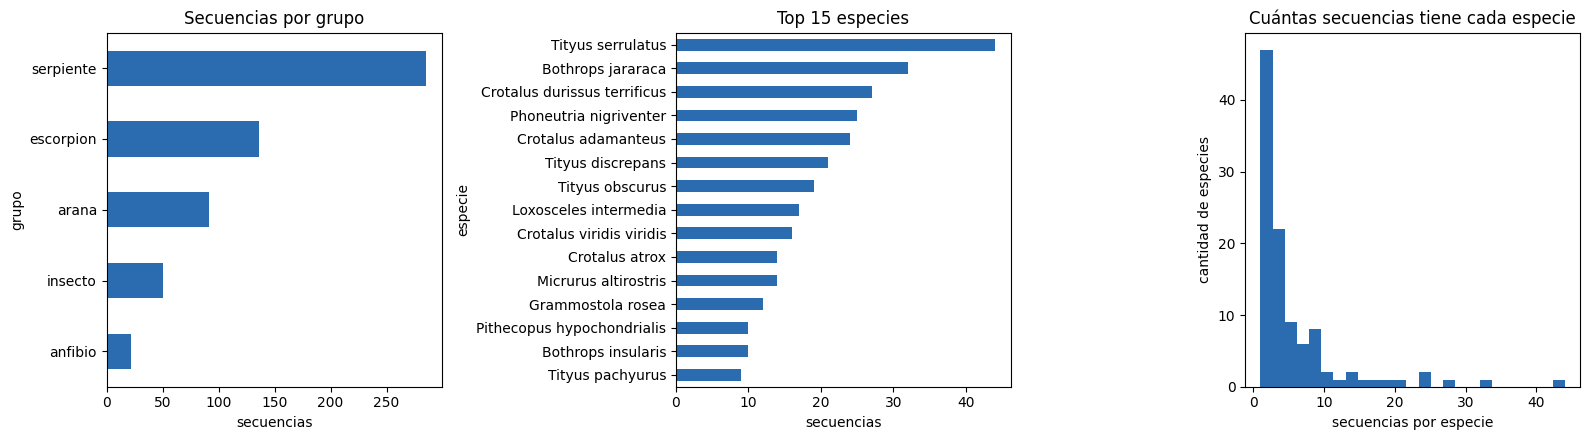

In [8]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.5))

por_grupo.sort_values().plot.barh(ax=ax1, color="#2b6cb0")
ax1.set_title("Secuencias por grupo")
ax1.set_xlabel("secuencias")

por_especie.head(15).sort_values().plot.barh(ax=ax2, color="#2b6cb0")
ax2.set_title("Top 15 especies")
ax2.set_xlabel("secuencias")

# Este histograma es el que muestra el desbalance de un vistazo:
# esperamos ver una barra altísima a la izquierda (muchas especies con poquitas secuencias)
ax3.hist(por_especie.values, bins=25, color="#2b6cb0")
ax3.set_title("Cuántas secuencias tiene cada especie")
ax3.set_xlabel("secuencias por especie")
ax3.set_ylabel("cantidad de especies")

plt.tight_layout()
plt.show()

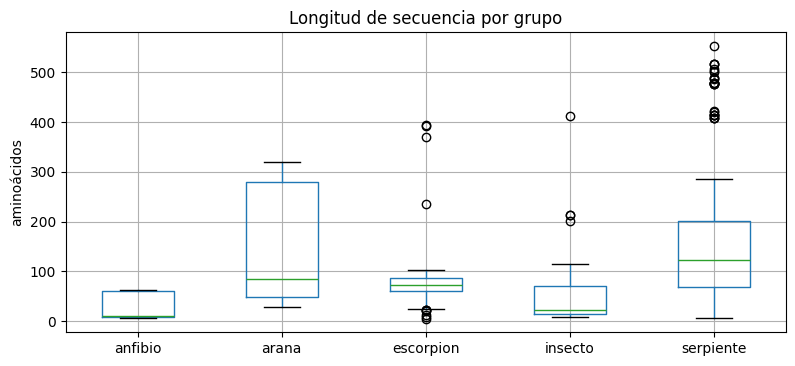

In [9]:
# Longitud de las secuencias según el grupo.
#
# Por qué miramos esto: los péptidos de piel de anfibio tienden a ser bastante más cortos
# que las toxinas de serpiente. Si las longitudes son muy distintas entre grupos, el modelo
# puede terminar aprendiendo "secuencia corta = anfibio" en vez de aprender biología.
# Daría buenos números por el motivo equivocado, y eso es peor que dar malos números.
df.boxplot(column="largo", by="grupo", figsize=(9, 4))
plt.suptitle("")
plt.title("Longitud de secuencia por grupo")
plt.ylabel("aminoácidos")
plt.xlabel("")
plt.show()

---

# 5. Entonces, ¿qué pregunta responde nuestro producto?

Nuestra idea original era clasificar **por especie**: dada una secuencia, decir de qué
animal viene. Pero después del hallazgo tuvimos que replantearlo.

### El problema de la pregunta original

Si serpientes y anfibios producen péptidos de la misma familia, pedirle al modelo que
distinga la especie es pedirle que separe cosas que **biológicamente se parecen**. Va a
fallar, y además va a fallar con razón.

Pero hay algo más de fondo, y es una pregunta de producto, no de modelo: *¿quién tiene una
secuencia y no sabe de qué animal salió?* Prácticamente nadie. La secuencia la produjo un
laboratorio que extrajo la muestra de un ejemplar identificado. **La especie ya la saben.**

Lo que un investigador sí necesita saber cuando tiene un péptido nuevo es: *"¿a qué familia
funcional pertenece y qué tan parecido es a algo que ya funcionó comercialmente?"*.

### Las cuatro opciones

| Nivel | Ejemplo | ¿Qué le aporta al usuario? |
|---|---|---|
| **Especie** | *Bothrops diporus* | Bajo: el usuario ya lo sabe |
| **Género** | *Bothrops* | Bajo, por lo mismo |
| **Grupo** | serpiente | Muy bajo |
| **Familia proteica** | péptido potenciador de bradiquinina | **Alto: es la pregunta que no sabe responder** |

La celda de abajo calcula, para cada nivel, cuántas clases quedan viables y qué porcentaje
del catálogo cubren.

> **Nuestra posición:** la familia proteica pasa a ser la salida principal y la especie
> queda como información secundaria. No la tiramos, pero deja de ser la promesa del
> producto. Y el score de novedad sigue siendo la pieza más valiosa de todas.


In [10]:
# Con menos de este número de secuencias, una clase no es modelable.
# Es una decisión nuestra: 5 es un mínimo bastante permisivo, elegido para no quedarnos
# sin clases.
MIN_POR_CLASE = 5

NIVELES = [
    ("grupo",     "grupo"),
    ("género",    "genero_consultado"),
    ("especie",   "especie"),
    ("fam.cruda", "familia_proteica"),   # el string completo de UniProt
    ("fam.niv1",  "familia_nivel1"),     # cortado en la primera coma
]

for nivel, col in NIVELES:
    conteo = df[col].value_counts()
    viables = conteo[conteo >= MIN_POR_CLASE]
    cobertura = df[col].isin(viables.index).mean()
    print(f"{nivel:8s}: {len(conteo):3d} clases totales | "
          f"{len(viables):3d} con >={MIN_POR_CLASE} secuencias | "
          f"cubren el {cobertura:.0%} del catálogo")

# Cuánto del catálogo no tiene familia asignada: si es mucho, clasificar por familia
# se complica y hay que decirlo.
sin_familia = (df["familia_proteica"] == "Sin familia asignada").mean()
print(f"\nSecuencias sin familia proteica asignada en UniProt: {sin_familia:.1%}")
if sin_familia > 0.3:
    print("Es bastante. Habrá que tratarlas como una clase aparte o excluirlas del")
    print("entrenamiento, y en cualquier caso explicarlo en la presentación.")

grupo   :   5 clases totales |   5 con >=5 secuencias | cubren el 100% del catálogo
género  :  16 clases totales |  13 con >=5 secuencias | cubren el 98% del catálogo
especie : 106 clases totales |  37 con >=5 secuencias | cubren el 76% del catálogo
fam.cruda: 101 clases totales |  32 con >=5 secuencias | cubren el 77% del catálogo
fam.niv1:  48 clases totales |  25 con >=5 secuencias | cubren el 92% del catálogo

Secuencias sin familia proteica asignada en UniProt: 3.6%


### Por qué cortamos el nombre de la familia en la primera coma

Al mirar las familias más grandes nos encontramos con esto:

```
Long (4 C-C) scorpion toxin superfamily, Sodium channel inhibitor family, Beta subfamily    43
Long (4 C-C) scorpion toxin superfamily, Sodium channel inhibitor family                    16
Long (4 C-C) scorpion toxin superfamily, Sodium channel inhibitor family, Alpha subfamily   13
```

Son **la misma familia**, escrita a tres niveles de detalle distintos. El campo de UniProt
no es un nombre: es una **ruta jerárquica**, como la dirección de una carpeta.

Usar el texto completo como etiqueta nos traía dos problemas serios:

1. **Partía familias reales en varias clases chicas.**
2. **Creaba clases anidadas unas dentro de otras.**

Al quedarnos con el primer nivel, los números mejoraron en todo sentido:

| | String completo | Primer nivel |
|---|---|---|
| Clases totales | 101 | 47 |
| Clases con ≥5 secuencias | 32 | **24** |
| Cobertura del catálogo | 77% | **92%** |
| Familias en más de un género | 13 de 32 (41%) | **11 de 24 (46%)** |
| Familias en más de un grupo | 4 de 32 | **5 de 24** |

Menos clases, más gordas, mejor cubiertas. Y además subió la proporción de familias que
cruzan géneros, que es justo lo que sostiene nuestro argumento.

In [11]:
# DECISIÓN FINAL: clasificamos por familia proteica de primer nivel.
NIVEL = "familia_nivel1"

df["clase"] = df[NIVEL]

conteo_nivel = df.loc[df["familia_valida"], NIVEL].value_counts()
clases_viables = conteo_nivel[conteo_nivel >= MIN_POR_CLASE].index

# Una secuencia es modelable si tiene familia anotada Y su familia tiene datos suficientes
df["clase_modelable"] = df["familia_valida"] & df[NIVEL].isin(clases_viables)

print(f"Nivel elegido: {NIVEL}")
print(f"  clases modelables : {len(clases_viables)}")
print(f"  secuencias usables: {df['clase_modelable'].sum()} de {len(df)}\n")

# El resto no se tira: es el material para evaluar la detección de novedad
sin_anotar = (~df["familia_valida"]).sum()
familia_rara = (df["familia_valida"] & ~df["clase_modelable"]).sum()
print("Conjunto de prueba para el detector de novedad:")
print(f"  de familias raras (vistas pocas veces) : {familia_rara}")
print(f"  sin familia asignada por UniProt       : {sin_anotar}")
print(f"  TOTAL                                  : {familia_rara + sin_anotar}")

# Chequeo del desbalance entre clases: con esto decidimos cómo evaluar el modelo
if len(conteo_nivel):
    ratio = conteo_nivel.iloc[0] / max(MIN_POR_CLASE, 1)
    print(f"\nClase más grande: {conteo_nivel.iloc[0]} secuencias ({conteo_nivel.index[0]})")
    print(f"Clase más chica : {MIN_POR_CLASE} secuencias -> desbalance de ~{ratio:.0f}x")
    print("Por eso evaluamos con macro-F1 y validación cruzada estratificada,")
    print("no con exactitud: la exactitud premia acertarle siempre a las clases grandes.")

Nivel elegido: familia_nivel1
  clases modelables : 24
  secuencias usables: 518 de 584

Conjunto de prueba para el detector de novedad:
  de familias raras (vistas pocas veces) : 45
  sin familia asignada por UniProt       : 21
  TOTAL                                  : 66

Clase más grande: 73 secuencias (Long (4 C-C) scorpion toxin superfamily)
Clase más chica : 5 secuencias -> desbalance de ~15x
Por eso evaluamos con macro-F1 y validación cruzada estratificada,
no con exactitud: la exactitud premia acertarle siempre a las clases grandes.


### OJO, las clases pequeñas no se tiran
>
> Marcamos las clases con pocas secuencias como "no modelables", pero **las dejamos en el
> archivo**. No son basura: son nuestro conjunto de prueba.
>
> Un péptido de una clase que el modelo nunca vio durante el entrenamiento
> es *exactamente* el caso que el detector de novedad tiene que saber marcar. Si lo
> reconoce como "esto no se parece a nada de lo que conozco", el detector funciona.
>
> O sea: la mayor limitación de nuestros datos termina siendo la forma de validar la parte
> más valiosa del producto. Es nuestro mejor argumento técnico y vale la pena contarlo así
> en la defensa.

## 6. Guardar el catálogo


In [12]:
COLUMNAS = ["accession", "nombre_proteina", "especie", "genero_consultado", "organism_id",
            "familia_proteica", "familia_nivel1", "familia_valida", "grupo", "en_nea",
            "largo", "peptido_corto", "sequence", "clase", "clase_modelable"]

# Nos quedamos solo con las columnas que existan, por si algún campo no vino de UniProt
columnas_ok = [c for c in COLUMNAS if c in df.columns]

catalogo = df[columnas_ok].reset_index(drop=True)
catalogo.to_csv("catalogo_nea.csv", index=False)

print(f"Guardado: catalogo_nea.csv -> {len(catalogo)} filas, {len(columnas_ok)} columnas")
print("\nEste archivo es la entrada del Notebook 2.")
catalogo.head()

Guardado: catalogo_nea.csv -> 584 filas, 15 columnas

Este archivo es la entrada del Notebook 2.


,accession,nombre_proteina,especie,genero_consultado,organism_id,familia_proteica,familia_nivel1,familia_valida,grupo,en_nea,largo,peptido_corto,sequence,clase,clase_modelable
0,I6L8L6,Basic phospholipase A2 homolog 2 (svPLA2 homol...,Bothrops brazili,Bothrops,157546,"Phospholipase A2 family, Group II subfamily, K...",Phospholipase A2 family,True,serpiente,False,121,False,SLFQLGKMILQETGKNPAASYGAYGCNCGVLGRGKPKDATDRCCYV...,Phospholipase A2 family,True
1,P04971,Thrombin-like enzyme batroxobin (BX) (SVTLE) (...,Bothrops atrox,Bothrops,8725,"Peptidase S1 family, Snake venom subfamily",Peptidase S1 family,True,serpiente,False,255,False,MVLIRVIANLLILQVSYAQKSSELVIGGDECDINEHPFLAFMYYSP...,Peptidase S1 family,True
2,P0C8M1,Basic phospholipase A2 BmTX-I (svPLA2) (EC 3.1...,Bothrops moojeni,Bothrops,98334,"Phospholipase A2 family, Group II subfamily, D...",Phospholipase A2 family,True,serpiente,False,121,False,DLWQFNKMIKKEVGKLPFPFYGAYGCYCGWGGRGEKPKDGTDRCCF...,Phospholipase A2 family,True
3,P0CC17,L-amino-acid oxidase (BatroxLAAO) (LAO) (EC 1....,Bothrops atrox,Bothrops,8725,"Flavin monoamine oxidase family, FIG1 subfamily",Flavin monoamine oxidase family,True,serpiente,False,506,False,MNVFFTFSLLFLAALGSCADDRNPLEECFRETDYEEFLEIAKNGLS...,Flavin monoamine oxidase family,True
4,P0CG03,Thrombin-like enzyme bhalternin (SVTLE) (EC 3....,Bothrops alternatus,Bothrops,64174,"Peptidase S1 family, Snake venom subfamily",Peptidase S1 family,True,serpiente,True,260,False,MVLIRVLANLLILQLSYAQKASELVIGGDECNINEHRSLVVLFNSS...,Peptidase S1 family,True


In [13]:
from google.colab import drive
drive.mount('/content/drive')
catalogo.to_csv('/content/drive/MyDrive/TPO_IA/catalogo_nea.csv', index=False)
print('Copiado a Drive')

ValueError: mount failed